In [328]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [329]:
df = pd.read_csv("smartcart_customers.csv")

In [330]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,2.325000,4.084821,2.662054,5.790179,5.316518,0.009375,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,1.932238,2.778714,2.923101,3.250958,2.426645,0.096391,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000


In [331]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [332]:
df.duplicated().sum()

np.int64(0)

# Missing value


In [333]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [334]:
df.isnull().sum()


ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

# Feature Engineering

In [335]:
df["Age"] = 2026-df["Year_Birth"]

In [336]:
df["Dt_Customer"]= pd.to_datetime(df["Dt_Customer"],dayfirst=True)

In [337]:
ref_date = df["Dt_Customer"].max()

df["Customer_Tenure_days"] = (ref_date-df["Dt_Customer"]).dt.days

In [338]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_days'],
      dtype='str')

In [339]:
df["Total_Spending"] = df["MntWines"] + df["MntFruits"] +df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] +   df["MntGoldProds"] 

In [340]:
df ["Total_children"] = df["Teenhome"] +  df["Kidhome"]

In [341]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [342]:
df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate",
    "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Master",
    "PhD": "Master"
})

In [343]:
print(df["Education"].value_counts())

Education
Graduate         1127
Master            856
Undergraduate     257
Name: count, dtype: int64


In [344]:
df["Living_With"] = df["Marital_Status"].replace({
    "Married": "Patner" , "Together": "Patner",
    "Single":"Alone" ,"Divorced":"Alone" , "Widow" :"Alone" ,
    "Alone":"Alone", "Absurd":"Alone" ,"YOLO":"Alone"
})

In [345]:
df.rename(columns={"Education ": "Education"}, inplace=True)

In [346]:
df["Education"].value_counts()

Education
Graduate         1127
Master            856
Undergraduate     257
Name: count, dtype: int64

In [347]:
df["Education"] = df["Education"].replace({
    "Basic": "Underg",
    "2n Cycle": "Underg",
    "Graduation": "Graduate",
    "Master": "Master",
    "PhD": "Master"
})

In [348]:
df["Education"] = df["Education"].str.strip()

In [349]:
df["Education"].value_counts()

Education
Graduate         1127
Master            856
Undergraduate     257
Name: count, dtype: int64

In [350]:
print(df.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Complain', 'Response', 'Age', 'Customer_Tenure_days', 'Total_Spending', 'Total_children', 'Living_With']


In [351]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_Spending,Total_children,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Patner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Patner
4,5324,1981,Master,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Patner


# Drop Columns

In [352]:
cols = ["ID", "Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spending_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

In [353]:
cols_to_drop = cols + spending_cols 

In [354]:
df_cleaned = df.drop(columns=cols_to_drop)

In [355]:
df_cleaned.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'Customer_Tenure_days', 'Total_Spending', 'Total_children',
       'Living_With'],
      dtype='str')

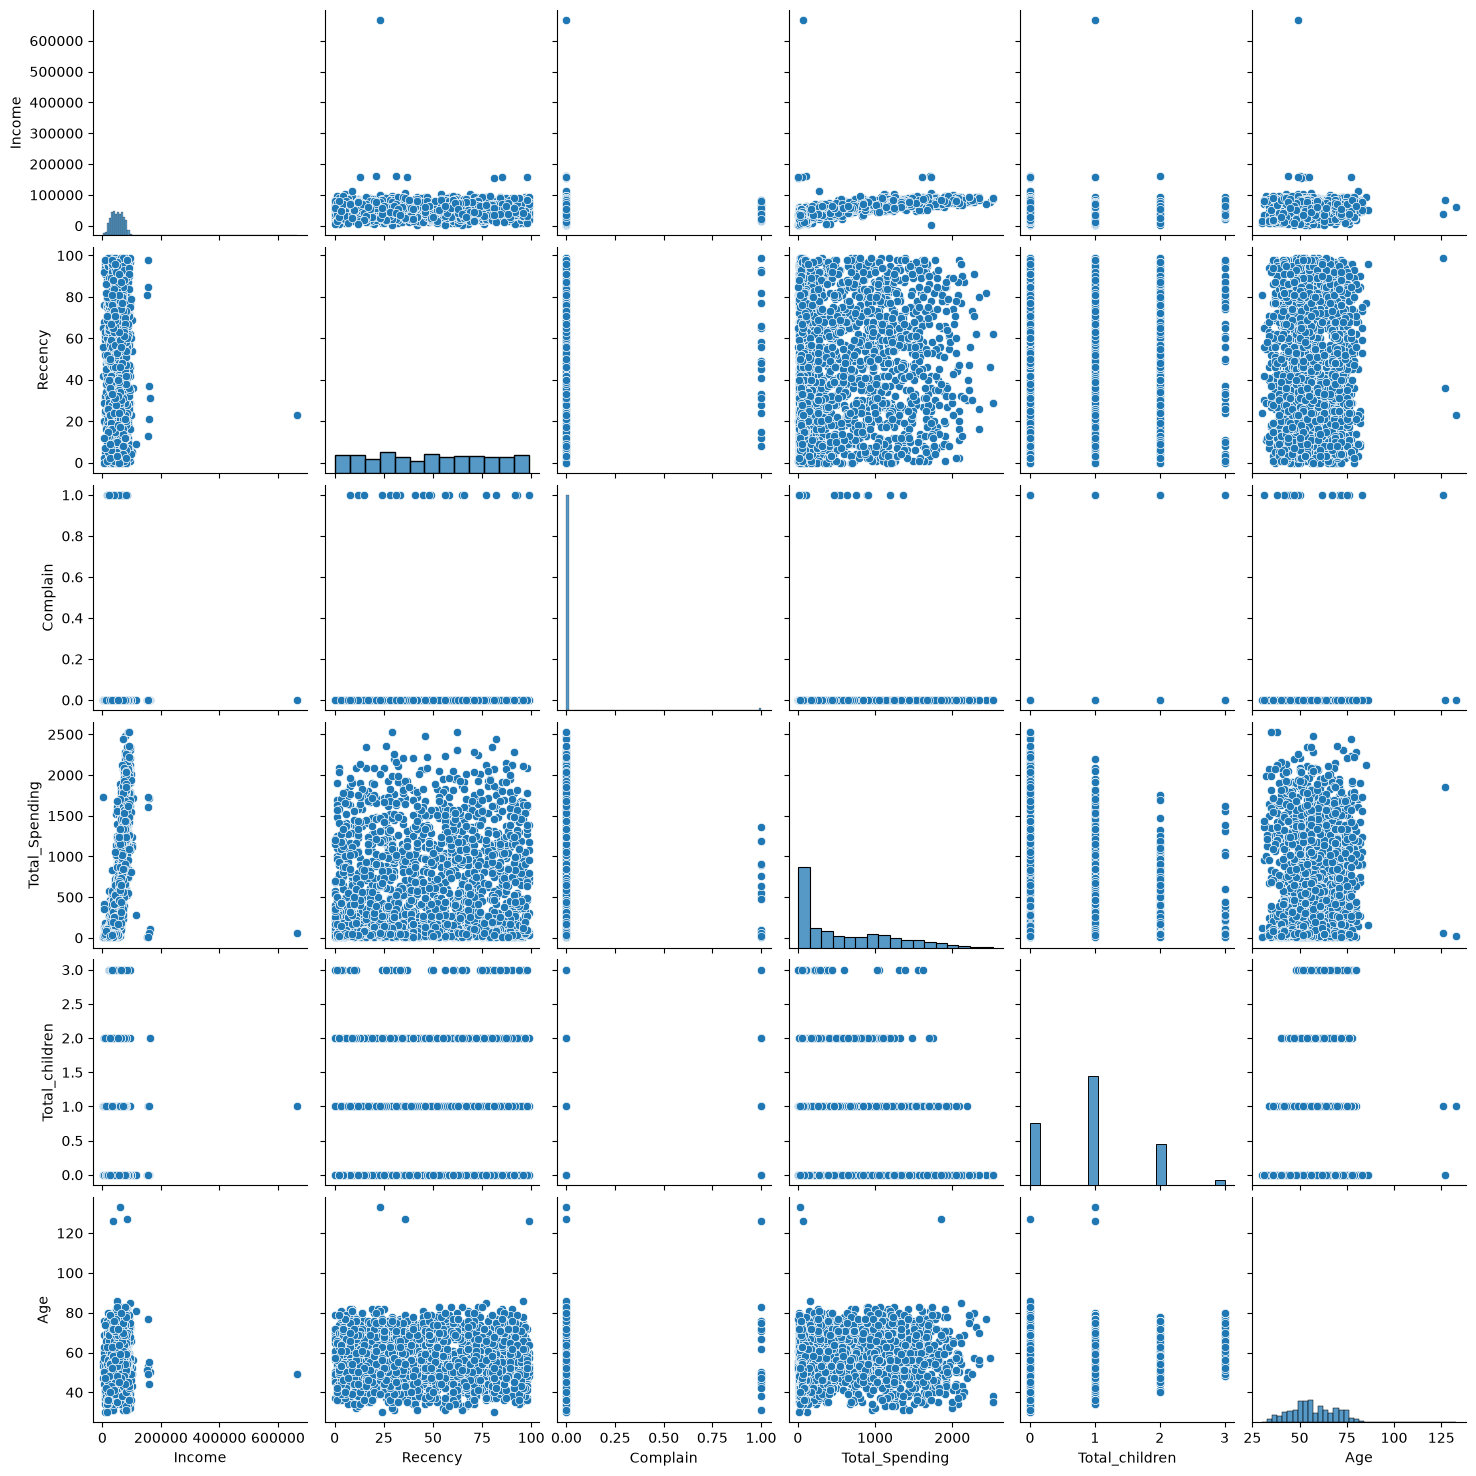

In [356]:
import seaborn as sns 
cols = ["Income","Recency","Complain","Total_Spending","Total_children","Age"]
sns.pairplot(df_cleaned[cols])

# Oulers

In [357]:
df_cleaned = df.drop(columns=cols_to_drop)

In [358]:
print("Data with outliers ",len(df_cleaned))

Data with outliers  2240


In [359]:
df_cleaned =df_cleaned[(df_cleaned["Age"]< 90)]
df_cleaned =df_cleaned[(df_cleaned["Income"]< 600_000)]
print("Data without outliers ",len(df_cleaned))

Data without outliers  2236


# heat map

In [360]:
corr = df_cleaned.corr(numeric_only=True)

<Axes: >

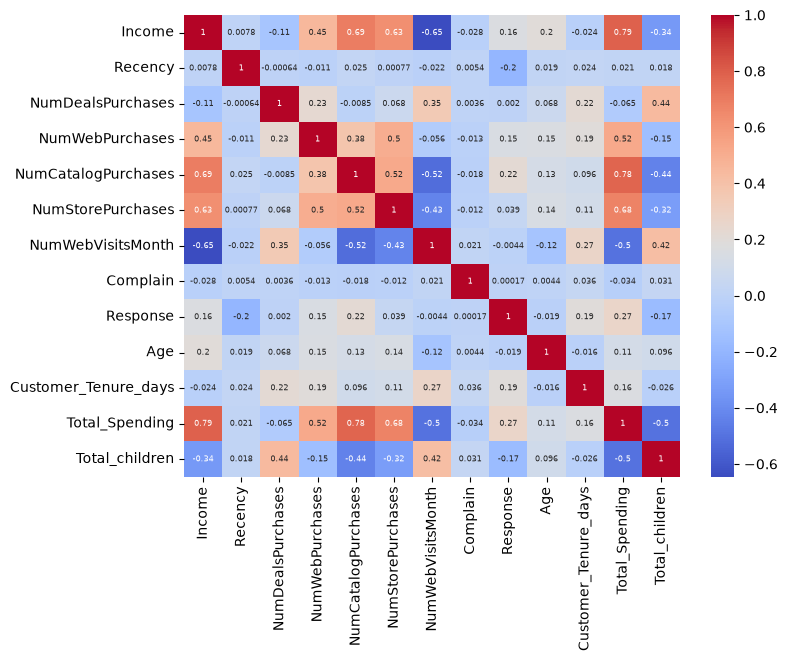

In [361]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)


# Encoding

In [362]:
from sklearn.preprocessing import OneHotEncoder

In [363]:
ohe = OneHotEncoder()

cat_cols = ["Education","Living_With"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [364]:
enc_df = pd.DataFrame(
    enc_cols.toarray(),
    columns=ohe.get_feature_names_out(cat_cols),
    index=df_cleaned.index
)

In [365]:
enc_df.head()

,Education_Graduate,Education_Master,Education_Undergraduate,Living_With_Alone,Living_With_Patner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [366]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_cols),enc_df],axis=1)

In [367]:
df_encoded.shape

(2236, 18)

# scaling 

In [368]:
from sklearn.preprocessing import StandardScaler

In [369]:
X = df_encoded

In [370]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Visualization

In [371]:
from sklearn.decomposition import PCA

In [372]:
pca = PCA(n_components = 4)

x_pca = pca.fit_transform(X_scaled)

Text(0.5, 0.92, '3d projection')

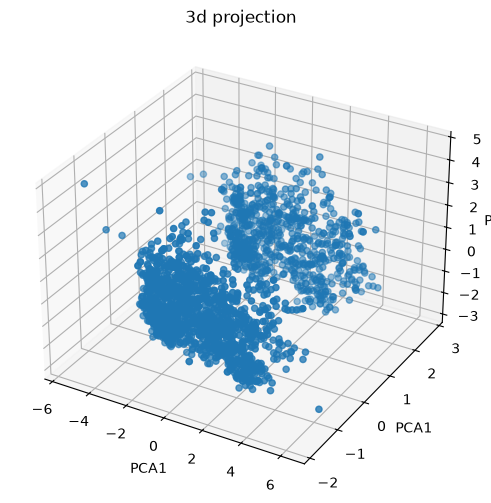

In [373]:
fig=plt.figure(figsize=(8,6))

ax=fig.add_subplot(111,projection="3d")

ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA1")
ax.set_zlabel("PCA1")
ax.set_title("3d projection")

In [374]:
pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815, 0.09912103])

# K value analysis

# 1 elbow method

In [375]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(x_pca)
    wcss.append(kmeans.inertia_)
    

In [376]:
knee = KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing")
optimal_k = knee.elbow

In [377]:
print("best k =", optimal_k)

best k = 5


Text(0, 0.5, 'WCSS')

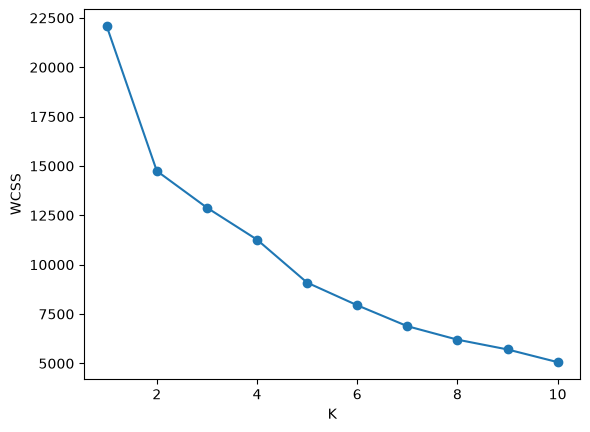

In [378]:
# plot

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("K")
plt.ylabel("WCSS")

# sihoutte score 

In [379]:
from sklearn.metrics import silhouette_score

Text(0, 0.5, 'Silhouette score')

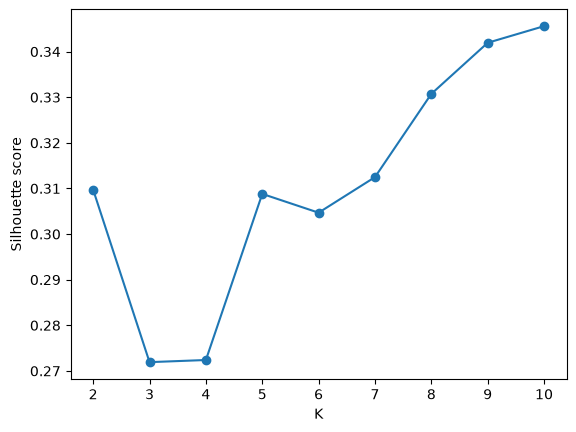

In [382]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(x_pca)
    score = silhouette_score(x_pca, labels)
    scores.append(score)

# plot
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette score")

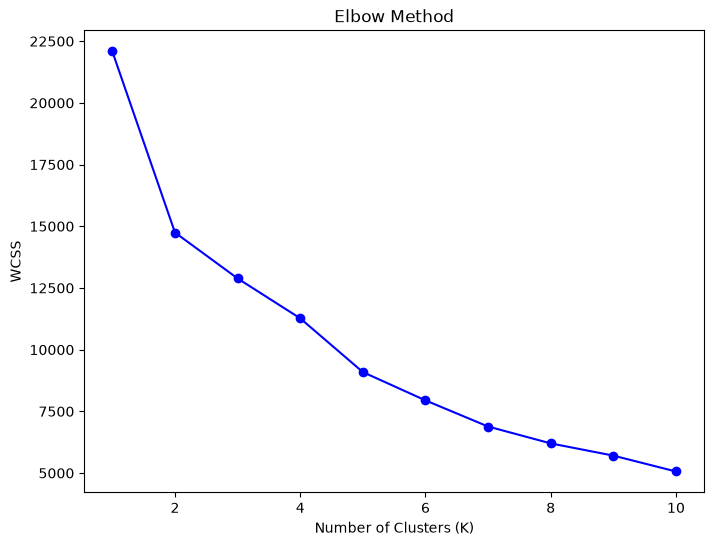

ValueError: x and y must have same first dimension, but have shapes (10,) and (9,)

In [383]:
k_range = range(1,11)

fig, ax1 = plt.subplots(figsize=(8,6))

ax1.plot(k_range, WCSS, marker="o", color="blue")

ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("WCSS")
ax1.set_title("Elbow Method")

plt.show()


ax2 = ax1.twinx()
ax2.plot(k_range,scores[:len(k_range)],marker="x",color="red")

Text(0, 0.5, 'SS')

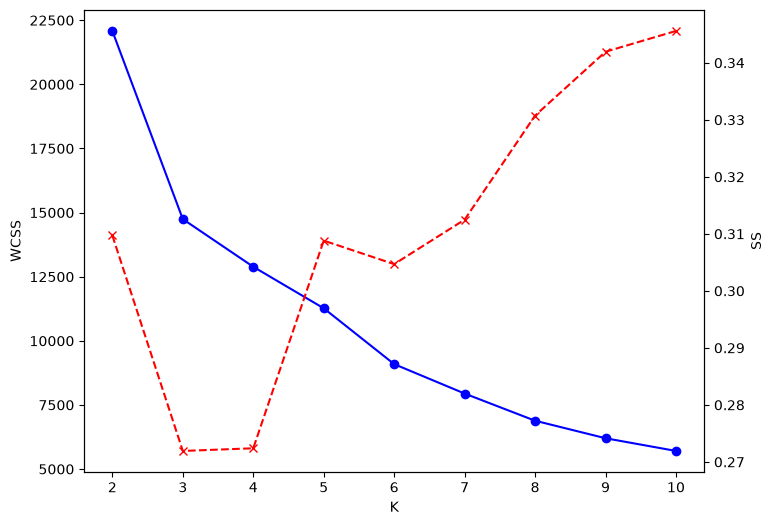

In [384]:


# combined plot

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(k_range, wcss[:len(k_range)], marker="o", color="blue") 
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker="x", color="red", linestyle="--")
ax2.set_ylabel("SS")


# clustering 

In [385]:
kmeans = KMeans(n_clusters=5,random_state=42)
labels_kmeans = kmeans.fit_predict(x_pca)

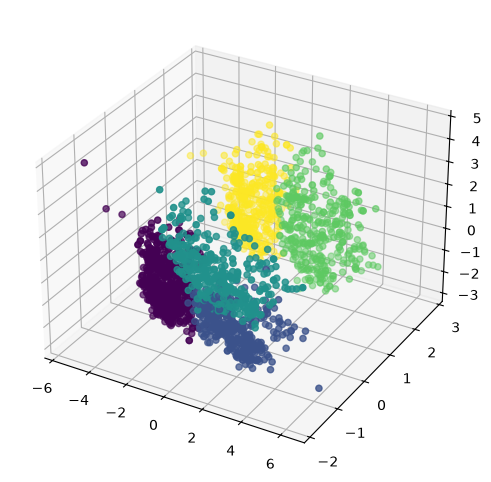

In [386]:

fig=plt.figure(figsize=(8,6))

ax=fig.add_subplot(111,projection="3d")

ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels_kmeans)


In [387]:
from sklearn.cluster import AgglomerativeClustering

In [388]:
agr = AgglomerativeClustering(n_clusters=4,linkage='ward')

labels_agr = agr.fit_predict(x_pca)

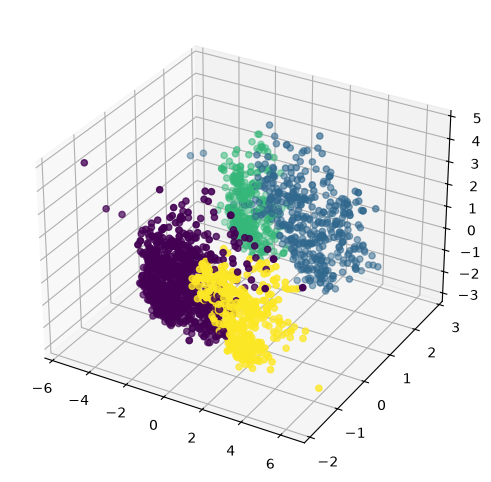

In [389]:

fig=plt.figure(figsize=(8,6))

ax=fig.add_subplot(111,projection="3d")

ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels_agr)


# chaterization of clusters 

In [396]:

X["cluster"] = labels_agr

In [397]:
X.head()


,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_days,Total_Spending,Total_children,Education_Graduate,Education_Master,Education_Undergraduate,Living_With_Alone,Living_With_Patner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,1
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

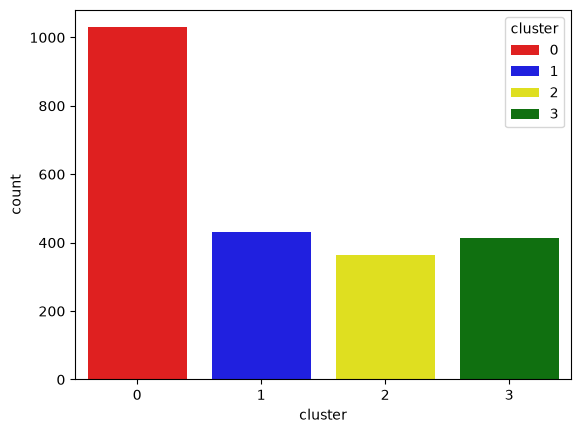

In [398]:
pal = ["red","blue","yellow","green"]

sns.countplot(x=X["cluster"],palette=pal,hue=X["cluster"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

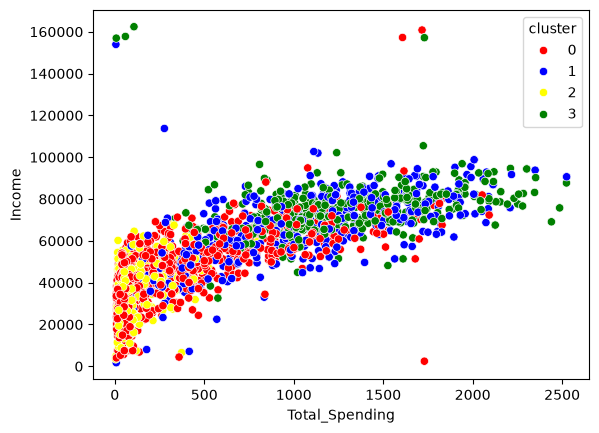

In [399]:
sns.scatterplot(x=X["Total_Spending"], y =X["Income"],hue=X["cluster"],palette=pal)
# Income & Spending patterns



In [400]:
# Cluster Summary

cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        42706.420797  49.697765           2.768707         3.635569   
1        66279.404651  49.439535           2.430233         5.700000   
2        35326.263736  49.038462           2.049451         2.189560   
3        74726.958838  47.399516           1.358354         5.208232   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   1.430515           4.661808           6.282799  0.010690   
1                   4.462791           7.893023           4.390698  0.006977   
2                   0.612637           3.269231           6.390110  0.010989   
3                   5.668281           8.663438           2.939467  0.004843   

         Response        Age  Customer_Tenure_days  Total_Spending  \
cluster         